# TP 3 : Classification / Modélisation

## Présentation de l'étude 

Les alcools de structures différentes sont fréquemment utilisés dans les produits d'hygiène et les cosmétiques. Il est souhaitable de classer ces alcools afin d'évaluer leurs effets nocifs potentiels à l'aide de méthodes moins coûteuses.
5 gaz sont particulièrement intéressants d'identifier : 

- 1-octanol, connu sous le nom d'alcool gras, avec son odeur forte, généralement utilisé dans les parfums et arômes;
- 1-propanol, ressemble beaucoup à l'alcool éthylique chimiquement avec une odeur forte et toxique, plutôt utilisé comme solvant;
- 2-butanol, alcool secondaire, est un solvant puissant;
- 2-propanol, alcool secondaire utilisé à la maison et dans l'industrie;
- 1-isobutanol, utilisé comme solvant.  

Le capteur QCM  (microbalance de cristal de quartz) est un dispositif physique qui est sensible aux changements de fréquence de résonance. Le but de l'étude est de mesurer l'action de différents capteurs QCM sur ces 5 alcools différents, et de déterminer quel type de capteur est le plus efficace dans la classification de ces alcools.

## Présentation des capteurs utilisés et des données générées

Pour cela, cinq capteurs QCM de gaz différents (QCM3, QCM6, QCM7, QCM10, QCM12) sont utilisés et cinq mesures de gaz différentes (1-octanol , 1-propanol, 2-butanol, 2-propanol et 1-isobutanol) sont effectuées pour chacun de ces capteurs.

L'échantillon de gaz passe à travers le capteur en cinq concentrations différentes. Ces concentrations sont :
  
    Rapport d'air (ml)   Rapport de gaz (ml) 
    0.799                0.201 
    0.700                0.300 
    0.600                0.400 
    0.501                0.499 
    0.400                0.600 

Les rapports  sur les polymères à empreintes moléculaires (MIP) et les nanoparticules (NP) utilisés dans les capteurs QCM sont :

    Capteur	 Ratio MIP   Ratio NP
      QCM3	      1	        1 
      QCM6          1	        0 
      QCM7	      1	        0.5 
      QCM10	     1            2 
      QCM12	     0	        1
      

## Références 

**Dataset :** https://archive.ics.uci.edu/ml/datasets/Alcohol+QCM+Sensor+Dataset

**Article :** M. Fatih Adak, Peter Lieberzeit, Purim Jarujamrus, Nejat Yumusak, *Classification of alcohols obtained by QCM sensors with different characteristics using ABC based neural network*, Engineering Science and Technology, an International Journal, 2019.
https://www.sciencedirect.com/science/article/pii/S2215098619303337?via%3Dihub

In [6]:
import numpy as np
from io import StringIO
import matplotlib.pyplot as plt
import sklearn 
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

In [7]:
# Afficher l'entête du jeu de données du capteur QCM3
fichier=open('QCM3.csv', "r")
print(fichier.readline())

# Charger l'ensemble de données et stocker dans la matrice Data
Data = np.genfromtxt('QCM3.csv',delimiter=";",skip_header=1,usecols = (range(0,10)))

# Afficher le jeu de données
print(Data)
print(Data.shape[1])

# Afficher les dimensions de la matrice des données
print("Dimensions de la matrice de donnees", Data.shape)

"0.799_0.201";"0.799_0.201";"0.700_0.300";"0.700_0.300";"0.600_0.400";"0.600_0.400";"0.501_0.499";"0.501_0.499";"0.400_0.600";"0.400_0.600";"1-Octanol";"1-Propanol";"2-Butanol";"2-propanol";"1-isobutanol"

[[ -10.06  -10.62  -14.43  -18.31  -24.64  -30.56  -38.62  -45.59  -54.89
   -62.28]
 [  -9.69  -10.86  -16.73  -21.75  -28.47  -35.83  -43.65  -52.43  -61.92
   -71.27]
 [ -12.07  -14.28  -21.54  -27.92  -35.19  -43.94  -52.04  -62.49  -71.97
   -83.1 ]
 [ -14.21  -17.41  -25.91  -33.36  -41.29  -51.27  -59.94  -71.55  -81.51
   -93.83]
 [ -16.57  -20.35  -29.97  -37.84  -47.03  -57.29  -67.13  -78.96  -90.01
  -102.65]
 [ -75.61  -64.1  -122.08 -102.17 -174.79 -145.5  -214.69 -177.3  -250.83
  -207.99]
 [ -76.28  -64.53 -123.4  -103.06 -174.74 -144.98 -206.75 -170.68 -240.14
  -200.05]
 [ -76.96  -65.37 -124.5  -103.87 -169.93 -140.56 -200.89 -165.88 -232.82
  -194.7 ]
 [ -78.29  -66.49 -125.78 -104.77 -165.42 -136.17 -196.1  -161.99 -226.89
  -189.57]
 [ -79.62  -66.85 -126.61 -10

# I. Classification non supervisée :  méthode des K-moyennes (K-means)

Cet algorithme est dû à   James MacQueen (1967). C'est une technique de classification non supervisée très utilisée car simple à  implémenter. L'idée principale est de partitionner un ensemble de données en $k$ classes. On définit et initialise les k centres représentant chaque classe :

$$\mathcal{C} = \left\{\mathcal{C}^1,..,\mathcal{C}^k\right\}$$

On associe alors à  chaque point/donnée le centre le plus proche au sens d'une certaine distance. Dans le cadre non supervisé on cherche généralement à  partitionner l'ensemble de données de manière à  minimiser la variance intra-classe, qui se traduit par l'énergie (ou isotropie) :

$$E = \frac{1}{n}\sum_{i=1}^k\sum_{x\in \mathcal{C}^i}\|x-m_i\|^2$$

où
$\begin{cases}
  S = {x_1,..,x_n} \text{ensemble des données}\\
  \#S = n\\
  \mathcal{C}^i = \text{classe i } \forall i\in{1,..,k}\\
  m_i = \text{centre de la classe i\ }, \ \forall i \in \{1,..,k\}
\end{cases}$


<img src="./AlgoKmeans.png" width="800" height="800"  >


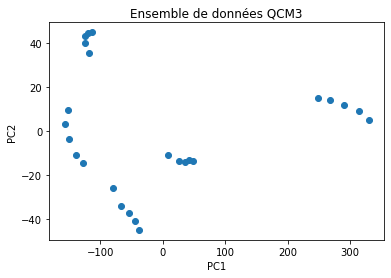

In [8]:
# Réduction de dimensions par ACP 

n_components=2
pca = PCA(n_components)
principalComponents = pca.fit_transform(Data)


# affichage des points
plt.scatter(principalComponents[:, 0], principalComponents[:, 1],marker='o')
plt.title("Ensemble de données QCM3")
plt.xlabel("PC1")
plt.ylabel("PC2");
plt.show()

Partition retournée [0 0 0 0 0 2 2 2 2 2 4 4 4 4 4 3 3 3 3 3 1 1 1 1 1]


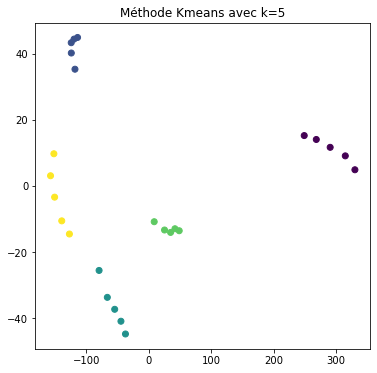

In [9]:
# Application de la méthode K-means 

y_pred = KMeans(n_clusters=5, init='random').fit_predict(principalComponents)

print('Partition retournée',y_pred)

# Affichage des clusters
plt.figure(figsize=(6, 6))
plt.scatter(principalComponents[:, 0], principalComponents[:, 1], c=y_pred)
plt.title("Méthode Kmeans avec k=5")
plt.show()

# Classification bayésienne 



In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(principalComponents, y_pred, test_size=0.20, random_state=42)

print('Dimension de la base apprentissage :',X_train.shape)
print('Dimension de la base test : ',X_test.shape)


Dimension de la base apprentissage : (20, 2)
Dimension de la base test :  (5, 2)


In [14]:
from sklearn.naive_bayes import GaussianNB

# chargement du modèle et de ses paramètres
clf = GaussianNB()
# Apprentissage du modèle et de ses paramètres à l'aide des données étiquettées, 
# c'est-à-dire de la base d'apprentissage, X_train et de ses labels y_train
clf.fit(X_train, y_train)

# Une fois le modèle appris, on teste ce modèle sur un nouveau jeu de données X_test
y_pred_Bayes=clf.predict(X_test)

# Evaluation des résultats de classification : 

- accuracy_score
- matrice de confusion 

<img src="./confusion_matrix.jpg" width="800" height="800"  >

D'autres métriques peuvent être calculées comme la précision et le rappel ou le F1-score. 
Ici nous nous intéressons à la matrice de confusion qui permet d'analyser où les erreurs de prédiction sont commises. 

In [15]:
from sklearn.metrics import accuracy_score

# Evaluation de la performance du modèle à l'aide de la vérité terrain y_test
print('Score de performance :',accuracy_score(y_test, y_pred_Bayes))

Score de performance : 1.0


In [16]:
# Evaluation du modèle appris sur la base d'apprentissage 
y_pred_train_Bayes=clf.predict(X_train)

print('Score de performance Base d Apprentissage :',accuracy_score(y_train, y_pred_train_Bayes))

Score de performance Base d Apprentissage : 1.0


In [17]:
from sklearn.metrics import confusion_matrix

confusion_matrix(y_train, y_pred_train_Bayes)

array([[4, 0, 0, 0, 0],
       [0, 4, 0, 0, 0],
       [0, 0, 4, 0, 0],
       [0, 0, 0, 4, 0],
       [0, 0, 0, 0, 4]])

# II. Modélisation : régression 


Soient $(X,Y)$ deux jeux de données tels que $Var(X)\neq 0$.
Il existe des constantes uniques $a$ et $b$ telles que l'équation $aX+b$ soit la meilleure approximation de $Y$ qui minimise l'erreur quadratique moyenne définie par : 
$$(a',b')\mapsto E((Y-(a'X+b'))^2)$$

Alors $$a=\frac{cov(X,Y)}{Var(X)} \text{ et } b=E(Y)-aE(X)$$


<img src="./regLin.jpeg" width="700" height="700"  >


et l'équation de la droite de régression est définie par : 
$$Y=\frac{cov(X,Y)}{Var(X)}*(X-E(X))+E(Y)$$

(5, 10)


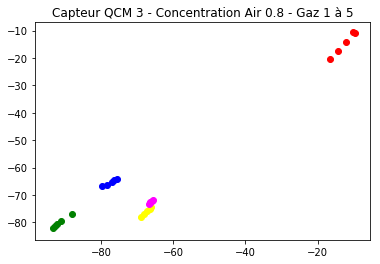

In [14]:
DataGaz1=Data[0:5,:]
DataGaz2=Data[5:10,:]
DataGaz3=Data[10:15,:]
DataGaz4=Data[15:20,:]
DataGaz5=Data[20:25,:]

print(DataGaz1.shape)

fig, ax = plt.subplots()
ax.set_title('Capteur QCM 3 - Concentration Air 0.8 - Gaz 1 à 5')
plt.scatter(DataGaz1[:, 0], DataGaz1[:, 1], c="red")
plt.scatter(DataGaz2[:, 0], DataGaz2[:, 1], c="blue")
plt.scatter(DataGaz3[:, 0], DataGaz3[:, 1], c="green")
plt.scatter(DataGaz4[:, 0], DataGaz4[:, 1], c="yellow")
plt.scatter(DataGaz5[:, 0], DataGaz5[:, 1], c="magenta")




Première concentration
coefficient directeur : 1.4484809794281897
Ordonnée à l'origine : 3.430981862440932
Première concentration
coefficient directeur : 0.7257949943442165
Ordonnée à l'origine : -9.326305597486169


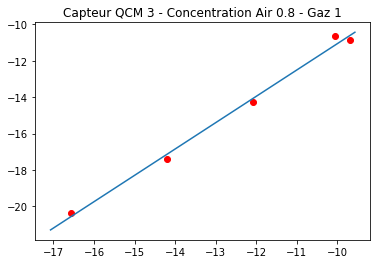

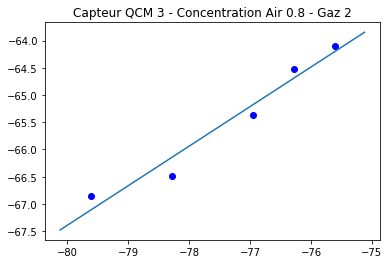

In [15]:
# Estimation de la droite de régression pour les 5 gaz suivant les concentrations

# Première concentration : Air 0.799 / Gaz 0.201 

print("Première concentration")
C=np.cov(DataGaz1[:, 0],DataGaz1[:, 1])

print("coefficient directeur :", C[0,1]/C[0,0])
print("Ordonnée à l'origine :",np.mean(DataGaz1[:, 1])-C[0,1]/C[0,0]*np.mean(DataGaz1[:, 0]))


#Affichage de la droite de régression pour Gaz 1
X_Pred=np.arange(min(DataGaz1[:, 0])-0.5,max(DataGaz1[:, 0])+0.5,0.5)
Y_dataGaz1_pred=C[0,1]/C[0,0]*(X_Pred-np.mean(DataGaz1[:, 0]))+np.mean(DataGaz1[:, 1])

fig2, ax2 = plt.subplots()
ax2.set_title('Capteur QCM 3 - Concentration Air 0.8 - Gaz 1')
plt.scatter(DataGaz1[:, 0], DataGaz1[:, 1], c="red")
plt.plot(X_Pred, Y_dataGaz1_pred)


print("Première concentration")
C=np.cov(DataGaz2[:, 0],DataGaz2[:, 1])

print("coefficient directeur :", C[0,1]/C[0,0])
print("Ordonnée à l'origine :",np.mean(DataGaz2[:, 1])-C[0,1]/C[0,0]*np.mean(DataGaz2[:, 0]))


#Affichage de la droite de régression 
X_Pred=np.arange(min(DataGaz2[:, 0])-0.5,max(DataGaz2[:, 0])+0.5,0.5)
Y_dataGaz2_pred=C[0,1]/C[0,0]*(X_Pred-np.mean(DataGaz2[:, 0]))+np.mean(DataGaz2[:, 1])

fig3, ax3 = plt.subplots()
ax3.set_title('Capteur QCM 3 - Concentration Air 0.8 - Gaz 2')
plt.scatter(DataGaz2[:, 0], DataGaz2[:, 1], c="blue")
plt.plot(X_Pred, Y_dataGaz2_pred)

Première concentration Gaz 1
coefficient directeur : [1.44848098]
Ordonnée à l'origine : [3.43098186]
Première concentration Gaz 2
coefficient directeur : [0.72579499]
Ordonnée à l'origine : [-9.3263056]
Première concentration Gaz 3
coefficient directeur : [0.95748063]
Ordonnée à l'origine : [7.5172192]
Première concentration Gaz 4
coefficient directeur : [1.31669091]
Ordonnée à l'origine : [12.62836549]
Première concentration Gaz 5
coefficient directeur : [1.37466237]
Ordonnée à l'origine : [18.47964081]


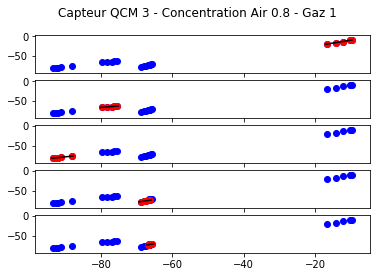

<Figure size 2160x1440 with 0 Axes>

In [16]:

CoeffDir=np.zeros((5,1))
OrdOrig=np.zeros((5,1))


fig, ax = plt.subplots(5, sharex=True, sharey=True)
plt.figure(figsize=(30,20))
fig.suptitle('Capteur QCM 3 - Concentration Air 0.8 - Gaz 1')

for i in range(1,6):
    listeData=np.arange((i-1)*5,i*5)

    print("Première concentration Gaz",i)
    C=np.cov(Data[listeData, 0],Data[listeData, 1])
    CoeffDir[i-1]=C[0,1]/C[0,0]
    OrdOrig[i-1]=np.mean(Data[listeData, 1])-C[0,1]/C[0,0]*np.mean(Data[listeData, 0])
    print("coefficient directeur :", CoeffDir[i-1])
    print("Ordonnée à l'origine :",OrdOrig[i-1])


    #Affichage de la droite de régression 
    X_Pred=np.arange(min(Data[listeData, 0])-0.5,max(Data[listeData, 0])+0.5,0.5)
    Y_data_pred=CoeffDir[i-1]*X_Pred+OrdOrig[i-1]

    ax[i-1].scatter(Data[:, 0], Data[:, 1], c="blue")
    ax[i-1].scatter(Data[listeData, 0], Data[listeData, 1], c="red")
    ax[i-1].plot(X_Pred, Y_data_pred,c="black")

# Travail demandé

Pour les autres capteurs :
- Réaliser une classification non supervisée après ACP en utilisant K-means;
- Réaliser une modélisation en considérant les différentes concentrations et les différents gaz.